# 03 - Exploratory plots: lime dose for a given ΔpH


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
MG_HA = 50.04 * 15 * 1.3 * 1e5 / 1e9          # Mg CCE/ha per mmolc/kg (15 cm, BD 1.3)
mg_axis = lambda ax, which="y": (ax.secondary_yaxis if which == "y" else ax.secondary_xaxis)(
    "right" if which == "y" else "top", functions=(lambda v: v * MG_HA, lambda v: v / MG_HA))

recs = pd.read_csv("../data/recs_harmonized.csv", keep_default_na=False, na_values=[""])
lim = pd.read_csv("../data/limer_harmonized.csv", keep_default_na=False, na_values=[""])
ok = lambda d: d[(d.dpH > 0) & (d.dose_dpH_mmolc_kg > 0)].assign(per_pH=lambda x: x.dose_dpH_mmolc_kg / x.dpH)
R, L = ok(recs), ok(lim)
print(f"recommendations: {len(R)} of {len(recs)} rows usable, {R.state.nunique()} states; limer: {len(L)} rows")

recommendations: 3171 of 3578 rows usable, 27 states; limer: 210 rows


## Coverage

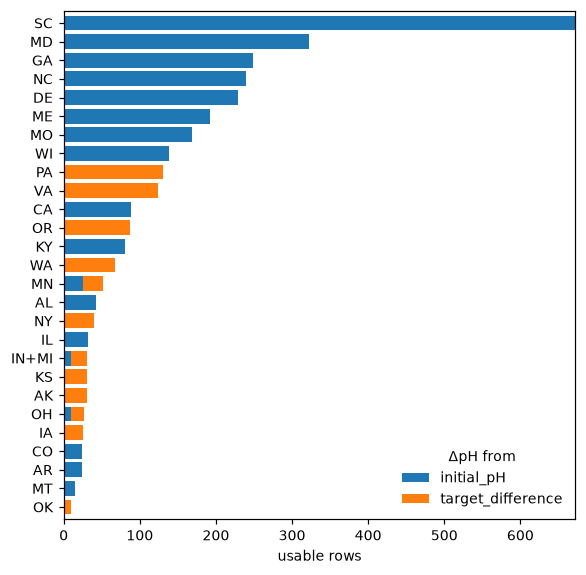

In [2]:
cov = R.groupby(["state", "dpH_basis"]).size().unstack(fill_value=0)
ax = cov.loc[cov.sum(axis=1).sort_values().index].plot.barh(stacked=True, figsize=(6, 6), width=0.8,
                                                           color={"initial_pH": "C0", "target_difference": "C1"})
ax.set_xlabel("usable rows"); ax.set_ylabel(""); ax.legend(title="ΔpH from", frameon=False);

## Dose vs. ΔpH

Each point is one recommendation (or one incubation step). The spread at a fixed ΔpH reflects differences in soil buffering and in how each state calibrated its tables.

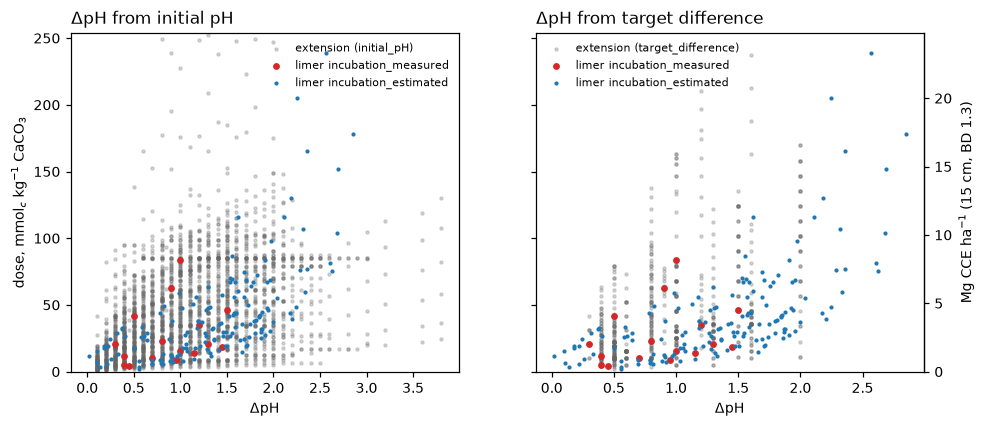

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (basis, g) in zip(axes, R.groupby("dpH_basis")):
    ax.scatter(g.dpH, g.dose_dpH_mmolc_kg, s=4, alpha=0.25, color="0.4", label=f"extension ({basis})")
    for kind, mk, col in [("incubation_measured", "o", "C3"), ("incubation_estimated", ".", "C0")]:
        q = L[L.kind == kind]
        ax.scatter(q.dpH, q.dose_dpH_mmolc_kg, s=12, marker=mk, color=col, label=f"limer {kind}")
    ax.set_xlabel("ΔpH"); ax.set_title(f"ΔpH from {basis.replace('_', ' ')}", loc="left")
    ax.legend(frameon=False, fontsize=7)
axes[0].set_ylabel("dose, mmol$_c$ kg$^{-1}$ CaCO$_3$")
axes[0].set_ylim(0, np.nanpercentile(R.dose_dpH_mmolc_kg, 99.5))
mg_axis(axes[1]).set_ylabel("Mg CCE ha$^{-1}$ (15 cm, BD 1.3)");

## Dose needed for a given ΔpH

Median and interquartile range of the dose in 0.25-unit ΔpH bins.

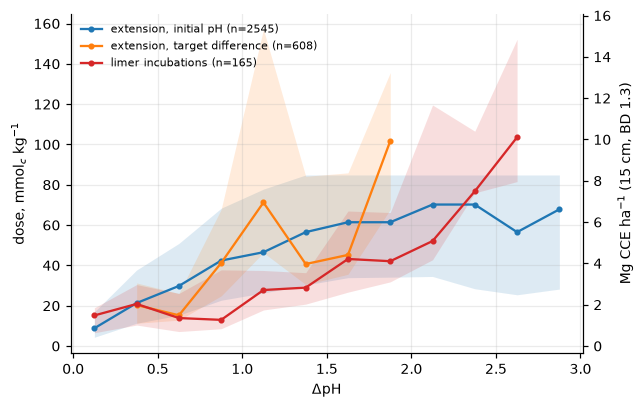

In [4]:
bins = np.arange(0, 3.01, 0.25)
def binned(d):
    g = d.groupby(pd.cut(d.dpH, bins), observed=True).dose_dpH_mmolc_kg
    out = g.quantile([0.25, 0.5, 0.75]).unstack().assign(n=g.size())
    out.index = [iv.mid for iv in out.index]
    return out[out.n >= 5]

fig, ax = plt.subplots(figsize=(6, 4))
for label, d, col in [("extension, initial pH", R[R.dpH_basis == "initial_pH"], "C0"),
                      ("extension, target difference", R[R.dpH_basis == "target_difference"], "C1"),
                      ("limer incubations", L[L.kind.str.startswith("incubation")], "C3")]:
    b = binned(d)
    ax.plot(b.index, b[0.5], "-o", ms=3, color=col, label=f"{label} (n={int(b.n.sum())})")
    ax.fill_between(b.index, b[0.25], b[0.75], color=col, alpha=0.15, lw=0)
ax.set_xlabel("ΔpH"); ax.set_ylabel("dose, mmol$_c$ kg$^{-1}$"); ax.legend(frameon=False, fontsize=7)
mg_axis(ax).set_ylabel("Mg CCE ha$^{-1}$ (15 cm, BD 1.3)");

## Are the two ΔpH bases comparable?

We calculate ΔpH from an initial pH and several targets for cases when both are available.

In [4]:
W = recs[(recs.dpH_basis == "initial_pH") & (recs.dose_kgCCE_ha > 0)]
rows = []
for (st, soil, p0), g in W.groupby(["state", "soil_id", "ph0"]):
    g = g.sort_values("ph_target")
    t, D = g.ph_target.values, g.dose_kgCCE_ha.values
    if len(g) >= 2 and t[0] - p0 >= 0.3:
        rows.append((st, D[0] / (t[0] - p0), (D[-1] - D[0]) / (t[-1] - t[0])))
C = pd.DataFrame(rows, columns=["state", "chord", "increment"]).assign(ratio=lambda d: d.increment / d.chord)
C.groupby("state").ratio.describe()[["count", "25%", "50%", "75%"]].round(2)

,count,25%,50%,75%
state,,,,
AL,18.0,0.80,0.86,0.99
DE,36.0,0.31,0.72,0.79
GA,48.0,0.00,0.16,0.51
KY,25.0,-0.10,0.71,0.83
ME,48.0,1.01,1.15,1.22
NC,56.0,1.00,1.00,1.00
SC,140.0,0.60,0.69,0.76
WI,19.0,1.45,1.54,1.66


## Lime per unit pH by state

Dose ÷ ΔpH for every row, i.e. the apparent buffer capacity each source implies. States are sorted by median.

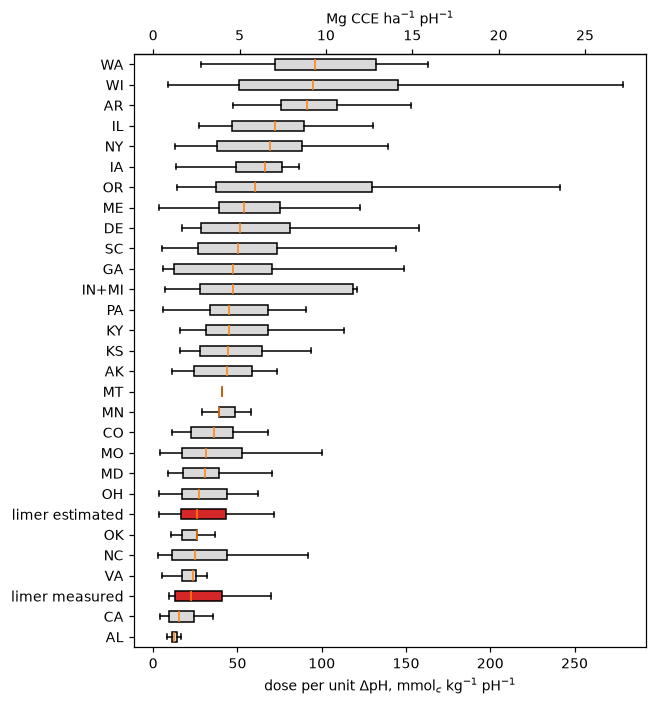

In [5]:
groups = {s: g.per_pH.values for s, g in R.groupby("state")}
groups |= {f"limer {k.split('_')[1]}": g.per_pH.values for k, g in L[L.kind.str.startswith("incubation")].groupby("kind")}
order = sorted(groups, key=lambda s: np.median(groups[s]))
fig, ax = plt.subplots(figsize=(6, 7))
bp = ax.boxplot([groups[s] for s in order], orientation="horizontal", tick_labels=order, showfliers=False, patch_artist=True)
for patch, s in zip(bp["boxes"], order):
    patch.set_facecolor("C3" if s.startswith("limer") else "0.85")
ax.set_xlabel("dose per unit ΔpH, mmol$_c$ kg$^{-1}$ pH$^{-1}$"); mg_axis(ax, "x").set_xlabel("Mg CCE ha$^{-1}$ pH$^{-1}$");

## Dose per pH unit versus starting pH

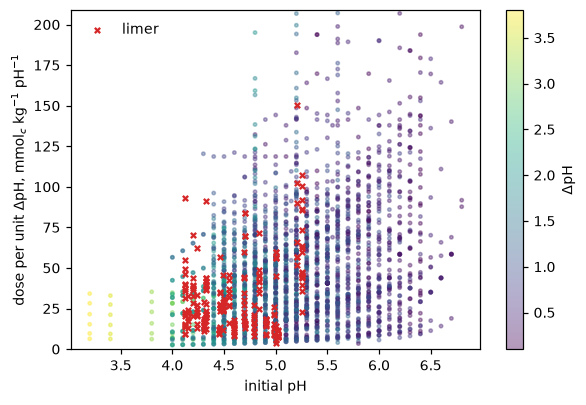

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
q = R[R.dpH_basis == "initial_pH"]
sc = ax.scatter(q.ph0, q.per_pH, c=q.dpH, s=5, alpha=0.4, cmap="viridis")
ax.scatter(L.ph0, L.per_pH, s=12, color="C3", marker="x", label="limer")
ax.set_xlabel("initial pH"); ax.set_ylabel("dose per unit ΔpH, mmol$_c$ kg$^{-1}$ pH$^{-1}$")
ax.set_ylim(0, np.nanpercentile(q.per_pH, 99)); ax.legend(frameon=False)
fig.colorbar(sc, ax=ax, label="ΔpH");

In [ ]:
# ---